<a href="https://colab.research.google.com/github/sreejareddy19/Deep-Learning-lab/blob/main/DL_CaseStudy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q tensorflow-datasets scikit-learn matplotlib pillow

In [2]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras import layers, models
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

SEED = 42
IMG_SIZE = 128
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
!pip install importlib_resources

In [4]:
# Load the dataset

dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True,
    shuffle_files=True
)

class_names = info.features["label"].names
NUM_CLASSES = len(class_names)

print("Total dataset images:", info.splits["train"].num_examples)
print("Number of disease classes:", NUM_CLASSES)
print("\nClass names:")

for name in class_names:
    print(name)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.HBRPOI_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Total dataset images: 54303
Number of disease classes: 38

Class names:
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry___healthy
Cherry___Powdery_mildew
Corn___Cercospora_leaf_spot Gray_leaf_spot
Corn___Common_rust
Corn___healthy
Corn___Northern_Leaf_Blight
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___healthy
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___healthy
Potato___Late_blight
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___healthy
Strawberry___Leaf_scorch
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___healthy
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Sp

In [5]:
import numpy as np
from collections import Counter

class_counts = Counter()

for images, labels in dataset:
    labels = labels.numpy().astype(int).flatten()
    class_counts.update(labels.tolist())

print("IMAGE COUNT IN EACH CLASS")
print("=" * 50)

for i, class_name in enumerate(class_names):
    print(f"{class_name}: {class_counts.get(i, 0)} images")

print("=" * 50)
print("Total images:", sum(class_counts.values()))
print("Total classes:", len(class_names))
print("Smallest class:", min(class_counts.get(i, 0) for i in range(len(class_names))))
print("Largest class:", max(class_counts.get(i, 0) for i in range(len(class_names))))

IMAGE COUNT IN EACH CLASS
Apple___Apple_scab: 630 images
Apple___Black_rot: 621 images
Apple___Cedar_apple_rust: 275 images
Apple___healthy: 1645 images
Blueberry___healthy: 1502 images
Cherry___healthy: 854 images
Cherry___Powdery_mildew: 1052 images
Corn___Cercospora_leaf_spot Gray_leaf_spot: 513 images
Corn___Common_rust: 1192 images
Corn___healthy: 1162 images
Corn___Northern_Leaf_Blight: 985 images
Grape___Black_rot: 1180 images
Grape___Esca_(Black_Measles): 1383 images
Grape___healthy: 423 images
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076 images
Orange___Haunglongbing_(Citrus_greening): 5507 images
Peach___Bacterial_spot: 2297 images
Peach___healthy: 360 images
Pepper,_bell___Bacterial_spot: 997 images
Pepper,_bell___healthy: 1477 images
Potato___Early_blight: 1000 images
Potato___healthy: 152 images
Potato___Late_blight: 1000 images
Raspberry___healthy: 371 images
Soybean___healthy: 5090 images
Squash___Powdery_mildew: 1835 images
Strawberry___healthy: 456 images
Strawberr

In [6]:
# select up to 300 real images per class

import numpy as np
import tensorflow as tf
import random
import gc
from collections import Counter
from sklearn.model_selection import train_test_split

MAX_IMAGES_PER_CLASS = 300
SEED = 42
IMG_SIZE = 128

random.seed(SEED)
np.random.seed(SEED)

samples = {i: [] for i in range(NUM_CLASSES)}
seen = Counter()

print("Scanning PlantVillage and selecting images...")

for image, label in dataset:
    label = int(label.numpy())
    seen[label] += 1

    if len(samples[label]) < MAX_IMAGES_PER_CLASS:
        resized = tf.image.resize(
            image, (IMG_SIZE, IMG_SIZE)
        ).numpy()
        samples[label].append(
            np.clip(resized, 0, 255).astype(np.uint8)
        )
    else:
        # Randomly replace a selected image to keep a fair sample
        j = random.randrange(seen[label])

        if j < MAX_IMAGES_PER_CLASS:
            resized = tf.image.resize(
                image, (IMG_SIZE, IMG_SIZE)
            ).numpy()
            samples[label][j] = (
                np.clip(resized, 0, 255).astype(np.uint8)
            )

# Combine the selected images and labels
X_list = []
y_list = []

for class_id in range(NUM_CLASSES):
    X_list.extend(samples[class_id])
    y_list.extend([class_id] * len(samples[class_id]))

X = np.stack(X_list)
y = np.asarray(y_list, dtype=np.int64)

del samples, X_list, y_list
gc.collect()

print("\nSelected images:", len(X))
print("Image shape:", X.shape)
print("\nImages selected per class:")

for i, name in enumerate(class_names):
    print(f"{name}: {np.sum(y == i)}")

print("\nSmallest class:", min(np.sum(y == i) for i in range(NUM_CLASSES)))
print("Largest class:", max(np.sum(y == i) for i in range(NUM_CLASSES)))

Scanning PlantVillage and selecting images...

Selected images: 11227
Image shape: (11227, 128, 128, 3)

Images selected per class:
Apple___Apple_scab: 300
Apple___Black_rot: 300
Apple___Cedar_apple_rust: 275
Apple___healthy: 300
Blueberry___healthy: 300
Cherry___healthy: 300
Cherry___Powdery_mildew: 300
Corn___Cercospora_leaf_spot Gray_leaf_spot: 300
Corn___Common_rust: 300
Corn___healthy: 300
Corn___Northern_Leaf_Blight: 300
Grape___Black_rot: 300
Grape___Esca_(Black_Measles): 300
Grape___healthy: 300
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 300
Orange___Haunglongbing_(Citrus_greening): 300
Peach___Bacterial_spot: 300
Peach___healthy: 300
Pepper,_bell___Bacterial_spot: 300
Pepper,_bell___healthy: 300
Potato___Early_blight: 300
Potato___healthy: 152
Potato___Late_blight: 300
Raspberry___healthy: 300
Soybean___healthy: 300
Squash___Powdery_mildew: 300
Strawberry___healthy: 300
Strawberry___Leaf_scorch: 300
Tomato___Bacterial_spot: 300
Tomato___Early_blight: 300
Tomato___healthy: 300

In [7]:
# Split into 80% training, 10% validation, 10% testing

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

# Create shared datasets for all three models
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train_raw, y_train)
).shuffle(
    len(y_train), seed=SEED, reshuffle_each_iteration=True
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val_raw, y_val)
)

test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test_raw, y_test)
)

print("Training images:", len(y_train))
print("Validation images:", len(y_val))
print("Testing images:", len(y_test))
print("Total images:", len(y_train) + len(y_val) + len(y_test))

Training images: 8981
Validation images: 1123
Testing images: 1123
Total images: 11227


In [8]:
# Prepare CNN datasets

def preprocess_cnn(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


cnn_train = (
    train_ds
    .map(preprocess_cnn, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

cnn_val = (
    val_ds
    .map(preprocess_cnn, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

cnn_test = (
    test_ds
    .map(preprocess_cnn, num_parallel_calls=2)
    .batch(BATCH_SIZE)
    .prefetch(1)
)

print("Image preprocessing completed.")

Image preprocessing completed.


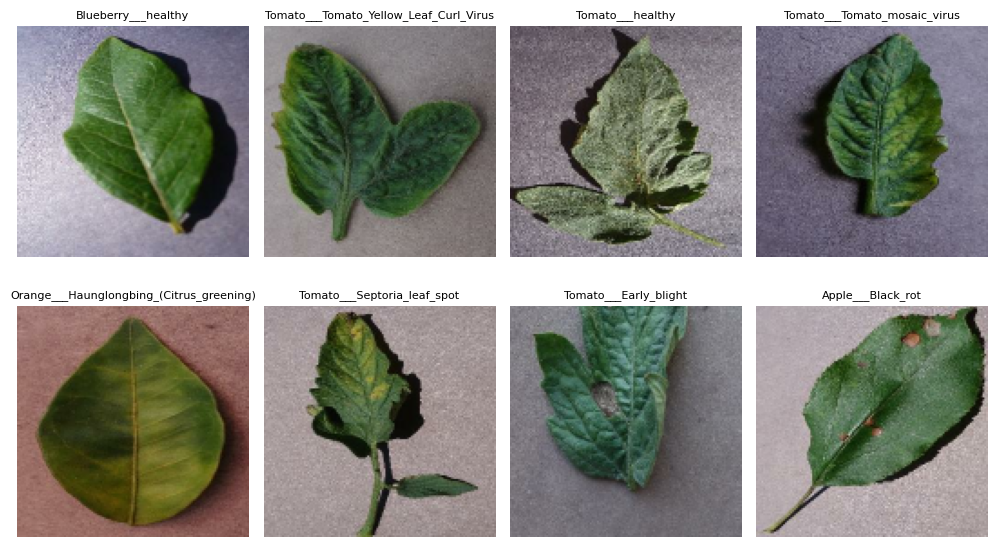

In [9]:
plt.figure(figsize=(10, 6))

for images, labels in cnn_train.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)

        plt.imshow(images[i].numpy())

        label_id = int(labels[i].numpy())
        plt.title(class_names[label_id], fontsize=8)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
# Build and train CNN

cnn_model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Convolution and pooling layers
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

cnn_history = cnn_model.fit(
    cnn_train,
    validation_data=cnn_val,
    epochs=5,
    callbacks=[early_stopping],
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         2,470 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,214 (118.02 KB)

 Trainable params: 30,214 (118.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.0648 - loss: 3.4326 - val_accuracy: 0.1167 - val_loss: 3.1269
Epoch 2/5
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.1530 - loss: 2.9367 - val_accuracy: 0.1861 - val_loss: 2.7215
Epoch 3/5
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.2185 - loss: 2.6138 - val_accuracy: 0.2894 - val_loss: 2.3988
Epoch 4/5
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.2578 - loss: 2.4509 - val_accuracy: 0.3286 - val_loss: 2.2086
Epoch 5/5
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.3249 - loss: 2.2492 - val_accuracy: 0.4203 - val_loss: 1.9387


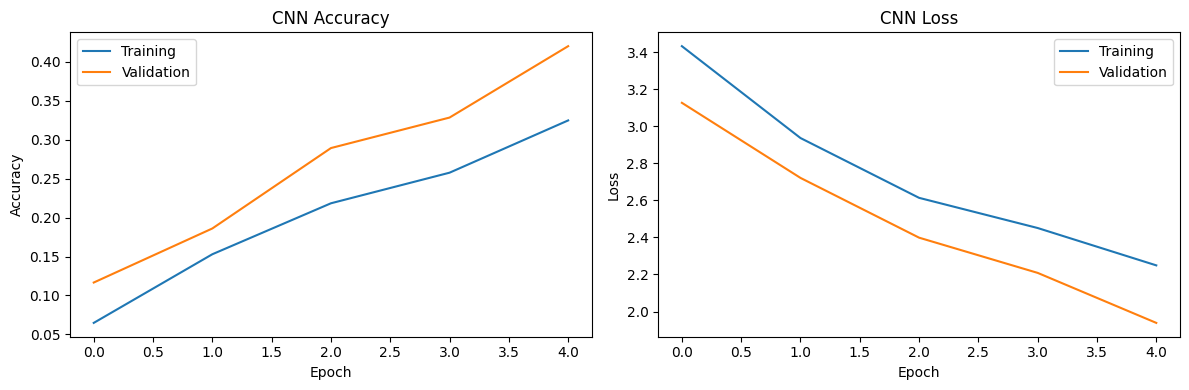

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="Training")
plt.plot(cnn_history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="Training")
plt.plot(cnn_history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
test_loss, test_accuracy = cnn_model.evaluate(
    cnn_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4194 - loss: 1.9890
Test Loss: 1.9890
Test Accuracy: 41.94%


In [13]:
cnn_model.save("/content/crop_cnn.keras")

print("CNN model saved successfully.")

CNN model saved successfully.


In [14]:
# Prepare VGG16 datasets

IMG_SIZE = 128
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

def preprocess_vgg(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.keras.applications.vgg16.preprocess_input(
        tf.cast(image, tf.float32)
    )
    return image, label

vgg_train = train_ds.map(
    preprocess_vgg, num_parallel_calls=2
).batch(BATCH_SIZE).prefetch(1)

vgg_val = val_ds.map(
    preprocess_vgg, num_parallel_calls=2
).batch(BATCH_SIZE).prefetch(1)

vgg_test = test_ds.map(
    preprocess_vgg, num_parallel_calls=2
).batch(BATCH_SIZE).prefetch(1)

print("VGG16 datasets prepared.")

VGG16 datasets prepared.


In [15]:
# Build and train VGG16

vgg_base = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

vgg_base.trainable = False

vgg_model = tf.keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    vgg_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

vgg_model.summary()

vgg_history = vgg_model.fit(
    vgg_train,
    validation_data=vgg_val,
    epochs=3,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=1,
            restore_best_weights=True
        )
    ],
    verbose=1
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,785,254 (56.40 MB)

 Trainable params: 70,566 (275.65 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/3
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 35s 27ms/step - accuracy: 0.5191 - loss: 1.8661 - val_accuracy: 0.8059 - val_loss: 0.6422
Epoch 2/3
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 27s 24ms/step - accuracy: 0.7661 - loss: 0.7497 - val_accuracy: 0.8744 - val_loss: 0.4369
Epoch 3/3
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 43s 26ms/step - accuracy: 0.8286 - loss: 0.5332 - val_accuracy: 0.8709 - val_loss: 0.4072


In [16]:
# Evaluate and save VGG16

vgg_val_loss, vgg_val_accuracy = vgg_model.evaluate(
    vgg_val, verbose=1
)

vgg_test_loss, vgg_test_accuracy = vgg_model.evaluate(
    vgg_test, verbose=1
)

print(f"VGG16 validation accuracy: {vgg_val_accuracy * 100:.2f}%")
print(f"VGG16 test accuracy: {vgg_test_accuracy * 100:.2f}%")

vgg_model.save("/content/crop_vgg16.keras")

141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.8709 - loss: 0.4072
141/141 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.8718 - loss: 0.4584
VGG16 validation accuracy: 87.09%
VGG16 test accuracy: 87.18%


In [17]:
# Release VGG16 memory

del vgg_model
del vgg_base

gc.collect()
tf.keras.backend.clear_session()

print("VGG16 model released from memory.")

VGG16 model released from memory.


In [18]:
# Prepare ResNet50 datasets

def preprocess_resnet(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.keras.applications.resnet50.preprocess_input(
        tf.cast(image, tf.float32)
    )
    return image, label

resnet_train = train_ds.map(
    preprocess_resnet, num_parallel_calls=2
).batch(BATCH_SIZE).prefetch(1)

resnet_val = val_ds.map(
    preprocess_resnet, num_parallel_calls=2
).batch(BATCH_SIZE).prefetch(1)

resnet_test = test_ds.map(
    preprocess_resnet, num_parallel_calls=2
).batch(BATCH_SIZE).prefetch(1)

print("ResNet50 datasets prepared.")

ResNet50 datasets prepared.


In [19]:
# Build and train ResNet50

resnet_base = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

resnet_base.trainable = False

resnet_model = tf.keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    resnet_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

resnet_history = resnet_model.fit(
    resnet_train,
    validation_data=resnet_val,
    epochs=3,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=1,
            restore_best_weights=True
        )
    ],
    verbose=1
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,854,886 (91.00 MB)

 Trainable params: 267,174 (1.02 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/3
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 48s 30ms/step - accuracy: 0.6485 - loss: 1.2064 - val_accuracy: 0.9083 - val_loss: 0.3226
Epoch 2/3
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - accuracy: 0.8388 - loss: 0.5018 - val_accuracy: 0.9127 - val_loss: 0.2648
Epoch 3/3
1123/1123 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.8780 - loss: 0.3636 - val_accuracy: 0.9110 - val_loss: 0.2461


In [20]:

# Evaluate and save ResNet50

resnet_val_loss, resnet_val_accuracy = resnet_model.evaluate(
    resnet_val, verbose=1
)

resnet_test_loss, resnet_test_accuracy = resnet_model.evaluate(
    resnet_test, verbose=1
)

print(f"ResNet50 validation accuracy: {resnet_val_accuracy * 100:.2f}%")
print(f"ResNet50 test accuracy: {resnet_test_accuracy * 100:.2f}%")

# Save the trained model
resnet_model.save("/content/crop_resnet50.keras")

# Initialize model_scores if it does not exist
if "model_scores" not in globals():
    model_scores = {}

# Store ResNet50 results
model_scores["ResNet50"] = {
    "validation_accuracy": float(resnet_val_accuracy),
    "test_accuracy": float(resnet_test_accuracy)
}

print("\nResNet50 model saved successfully!")
print("Model scores:", model_scores)


141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.9110 - loss: 0.2461
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9181 - loss: 0.2804
ResNet50 validation accuracy: 91.10%
ResNet50 test accuracy: 91.81%

ResNet50 model saved successfully!
Model scores: {'ResNet50': {'validation_accuracy': 0.9109528064727783, 'test_accuracy': 0.9180765748023987}}


Available model results: ['ResNet50']

Run or restore their evaluation results before comparing all three.


,Model,Validation Accuracy (%),Test Accuracy (%)
0,ResNet50,91.10%,91.81%


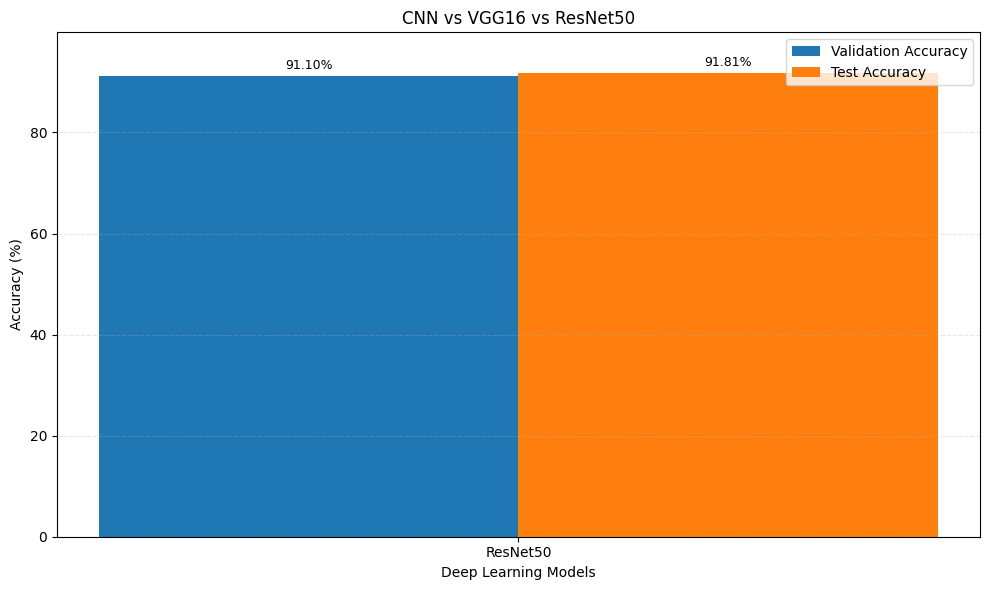

In [21]:

# ============================================
# Compare CNN, VGG16 and ResNet50
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Check whether model_scores exists
if "model_scores" not in globals() or not model_scores:
    raise ValueError(
        "model_scores is missing or empty. "
        "Run the model evaluation cells first."
    )

# 2. Check which model results are available
expected_models = ["CNN", "VGG16", "ResNet50"]

print("Available model results:", list(model_scores.keys()))

missing_models = [
    model for model in expected_models
    if model not in model_scores
]

if missing_models:
    print("\nWARNING: Results missing for:", missing_models)
    print("Run or restore their evaluation results before comparing all three.")

# 3. Create comparison table
comparison = pd.DataFrame([
    {
        "Model": name,
        "Validation Accuracy (%)":
            scores["validation_accuracy"] * 100,
        "Test Accuracy (%)":
            scores["test_accuracy"] * 100
    }
    for name, scores in model_scores.items()
    if "validation_accuracy" in scores
    and "test_accuracy" in scores
])

# Sort by validation accuracy
comparison = (
    comparison
    .sort_values("Validation Accuracy (%)", ascending=False)
    .reset_index(drop=True)
)

# Display results rounded to two decimal places
display(
    comparison.style.format({
        "Validation Accuracy (%)": "{:.2f}%",
        "Test Accuracy (%)": "{:.2f}%"
    })
)

# 4. Plot validation and test accuracy
x = np.arange(len(comparison))
width = 0.35

plt.figure(figsize=(10, 6))

validation_bars = plt.bar(
    x - width / 2,
    comparison["Validation Accuracy (%)"],
    width,
    label="Validation Accuracy"
)

test_bars = plt.bar(
    x + width / 2,
    comparison["Test Accuracy (%)"],
    width,
    label="Test Accuracy"
)

# Add accuracy labels above each bar
plt.bar_label(
    validation_bars,
    fmt="%.2f%%",
    padding=3,
    fontsize=9
)

plt.bar_label(
    test_bars,
    fmt="%.2f%%",
    padding=3,
    fontsize=9
)

plt.xticks(x, comparison["Model"])
plt.ylabel("Accuracy (%)")
plt.xlabel("Deep Learning Models")
plt.title("CNN vs VGG16 vs ResNet50")
plt.ylim(
    0,
    min(105, max(
        comparison["Validation Accuracy (%)"].max(),
        comparison["Test Accuracy (%)"].max()
    ) + 8)
)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

,Model,Validation Accuracy,Test Accuracy
0,ResNet50,0.910953,0.918077


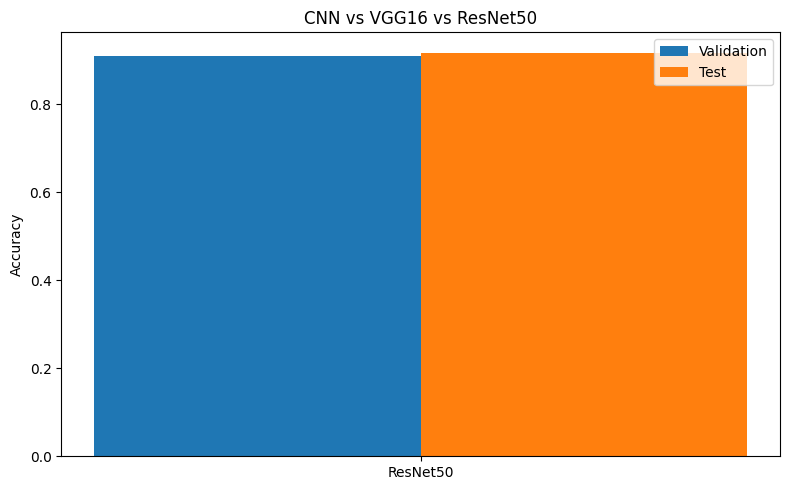

In [22]:
# Compare validation and test accuracy of CNN, VGG16 and ResNet50

comparison = pd.DataFrame([
    {
        "Model": name,
        "Validation Accuracy": scores["validation_accuracy"],
        "Test Accuracy": scores["test_accuracy"]
    }
    for name, scores in model_scores.items()
])

display(
    comparison.sort_values(
        "Validation Accuracy", ascending=False
    ).reset_index(drop=True)
)

plt.figure(figsize=(8, 5))

x = np.arange(len(comparison))
width = 0.35

plt.bar(
    x - width / 2,
    comparison["Validation Accuracy"],
    width,
    label="Validation"
)

plt.bar(
    x + width / 2,
    comparison["Test Accuracy"],
    width,
    label="Test"
)

plt.xticks(x, comparison["Model"])
plt.ylabel("Accuracy")
plt.title("CNN vs VGG16 vs ResNet50")
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
# Select the best model

best_name = max(
    model_scores,
    key=lambda name: model_scores[name]["validation_accuracy"]
)

model_paths = {
    "CNN": "/content/crop_cnn.keras",
    "VGG16": "/content/crop_vgg16.keras",
    "ResNet50": "/content/crop_resnet50.keras"
}

print("Selected model:", best_name)
print(
    "Validation accuracy:",
    f"{model_scores[best_name]['validation_accuracy'] * 100:.2f}%"
)

Selected model: ResNet50
Validation accuracy: 91.10%


In [24]:
import gc
import tensorflow as tf

model_paths = {
    "CNN": "/content/crop_cnn.keras",
    "VGG16": "/content/crop_vgg16.keras",
    "ResNet50": "/content/crop_resnet50.keras"
}

best_model = tf.keras.models.load_model(model_paths[best_name])

print("Best model loaded:", best_name)

Best model loaded: ResNet50


Saving WhatsApp Image 2026-09-07 at 4.03.22 PM.jpeg to WhatsApp Image 2026-09-07 at 4.03.22 PM.jpeg


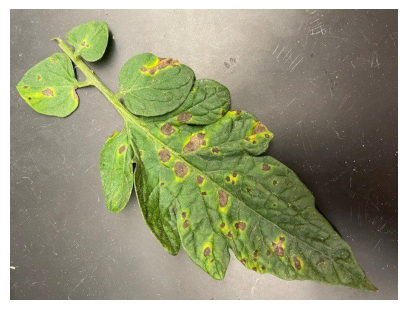

In [25]:
# Upload the leaf image

from google.colab import files
from PIL import Image
import matplotlib.pyplot as plt

uploaded = files.upload()

image_path = next(iter(uploaded.keys()))
leaf_image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(5, 5))
plt.imshow(leaf_image)
plt.axis("off")
plt.show()

In [26]:
# Prediction

import numpy as np

image_resized = leaf_image.resize((IMG_SIZE, IMG_SIZE))
image_array = np.array(image_resized, dtype=np.float32)

if best_name == "CNN":
    image_array = image_array / 255.0
elif best_name == "VGG16":
    image_array = tf.keras.applications.vgg16.preprocess_input(image_array)
else:
    image_array = tf.keras.applications.resnet50.preprocess_input(image_array)

image_array = np.expand_dims(image_array, axis=0)

probabilities = best_model.predict(image_array, verbose=0)[0]

predicted_index = int(np.argmax(probabilities))
predicted_class = class_names[predicted_index]
confidence = float(probabilities[predicted_index])

if "___" in predicted_class:
    crop_name, disease_name = predicted_class.split("___", 1)
else:
    crop_name, disease_name = "Unknown", predicted_class

print("Selected model:", best_name)
print("Crop:", crop_name)
print("Predicted disease:", disease_name.replace("_", " "))
print(f"Confidence: {confidence * 100:.2f}%")

Selected model: ResNet50
Crop: Tomato
Predicted disease: Late blight
Confidence: 70.40%


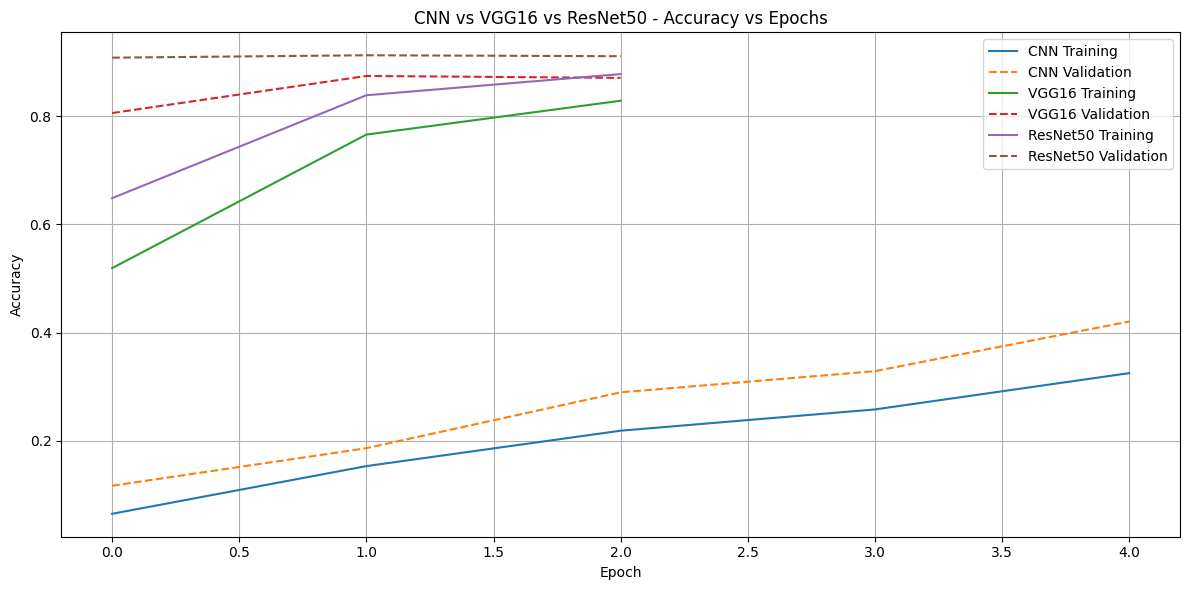

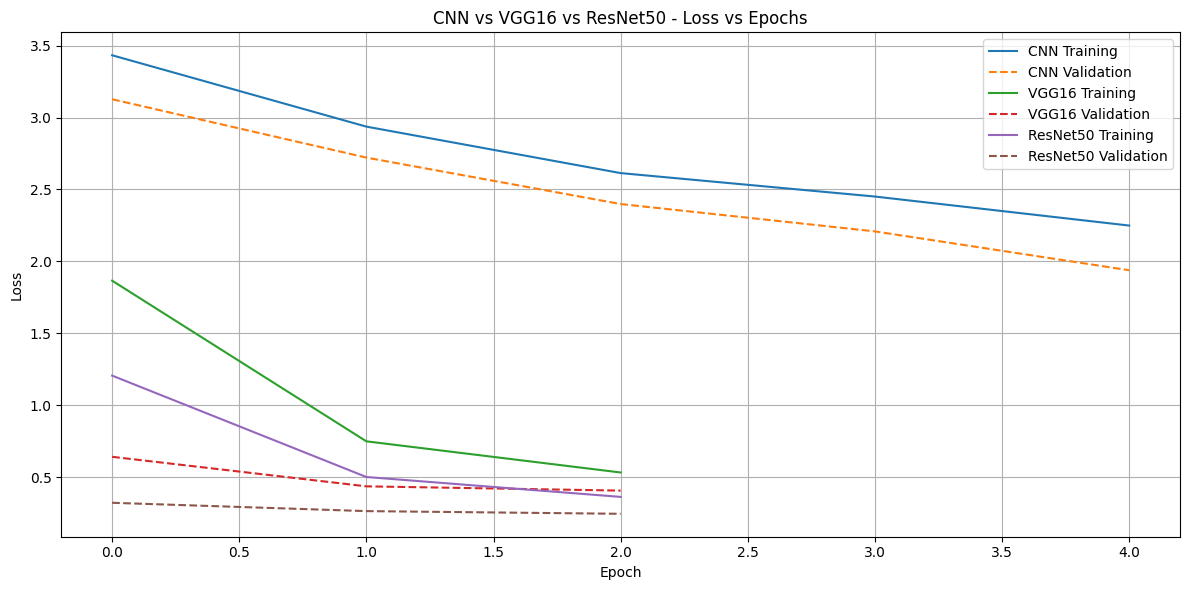

In [27]:

import matplotlib.pyplot as plt

# Training histories already available in your notebook
histories = {
    "CNN": cnn_history,
    "VGG16": vgg_history,
    "ResNet50": resnet_history
}

# Accuracy vs epochs
plt.figure(figsize=(12, 6))

for name, hist in histories.items():
    plt.plot(
        hist.history["accuracy"],
        label=f"{name} Training"
    )
    plt.plot(
        hist.history["val_accuracy"],
        linestyle="--",
        label=f"{name} Validation"
    )

plt.title("CNN vs VGG16 vs ResNet50 - Accuracy vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Loss vs epochs
plt.figure(figsize=(12, 6))

for name, hist in histories.items():
    plt.plot(
        hist.history["loss"],
        label=f"{name} Training"
    )
    plt.plot(
        hist.history["val_loss"],
        linestyle="--",
        label=f"{name} Validation"
    )

plt.title("CNN vs VGG16 vs ResNet50 - Loss vs Epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



CNN accuracy: 41.94%
Test samples: 1123


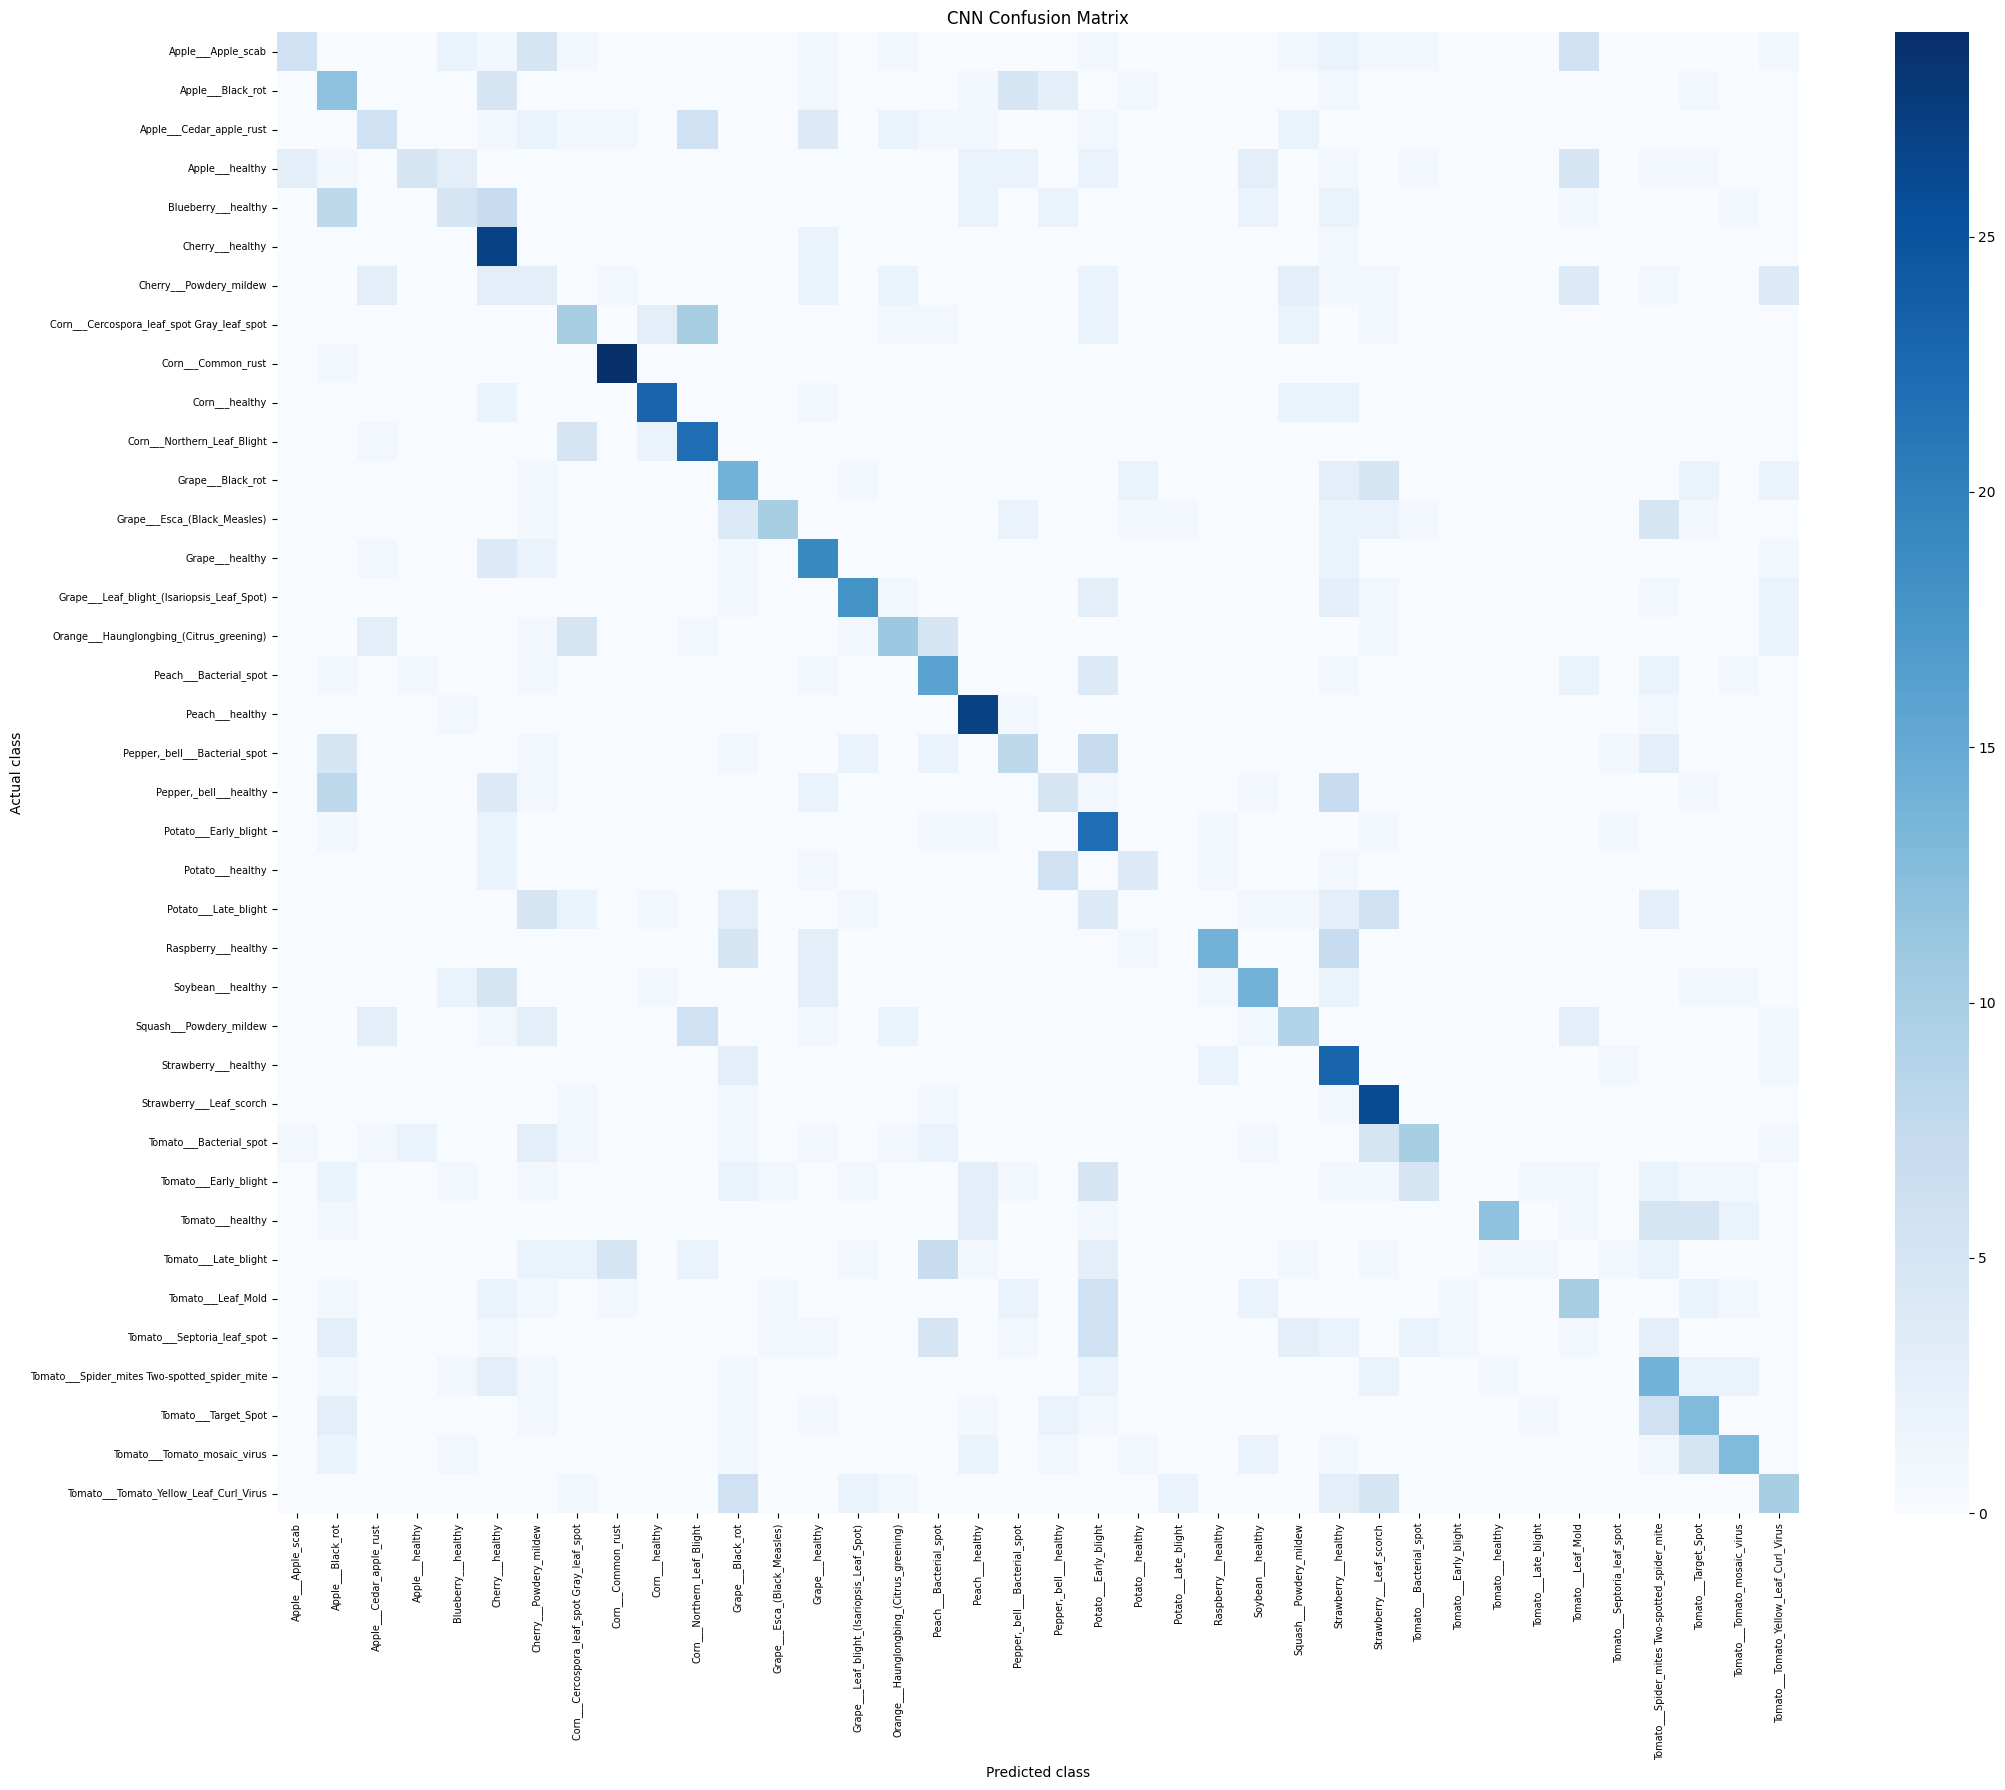


VGG16 accuracy: 91.81%
Test samples: 1123


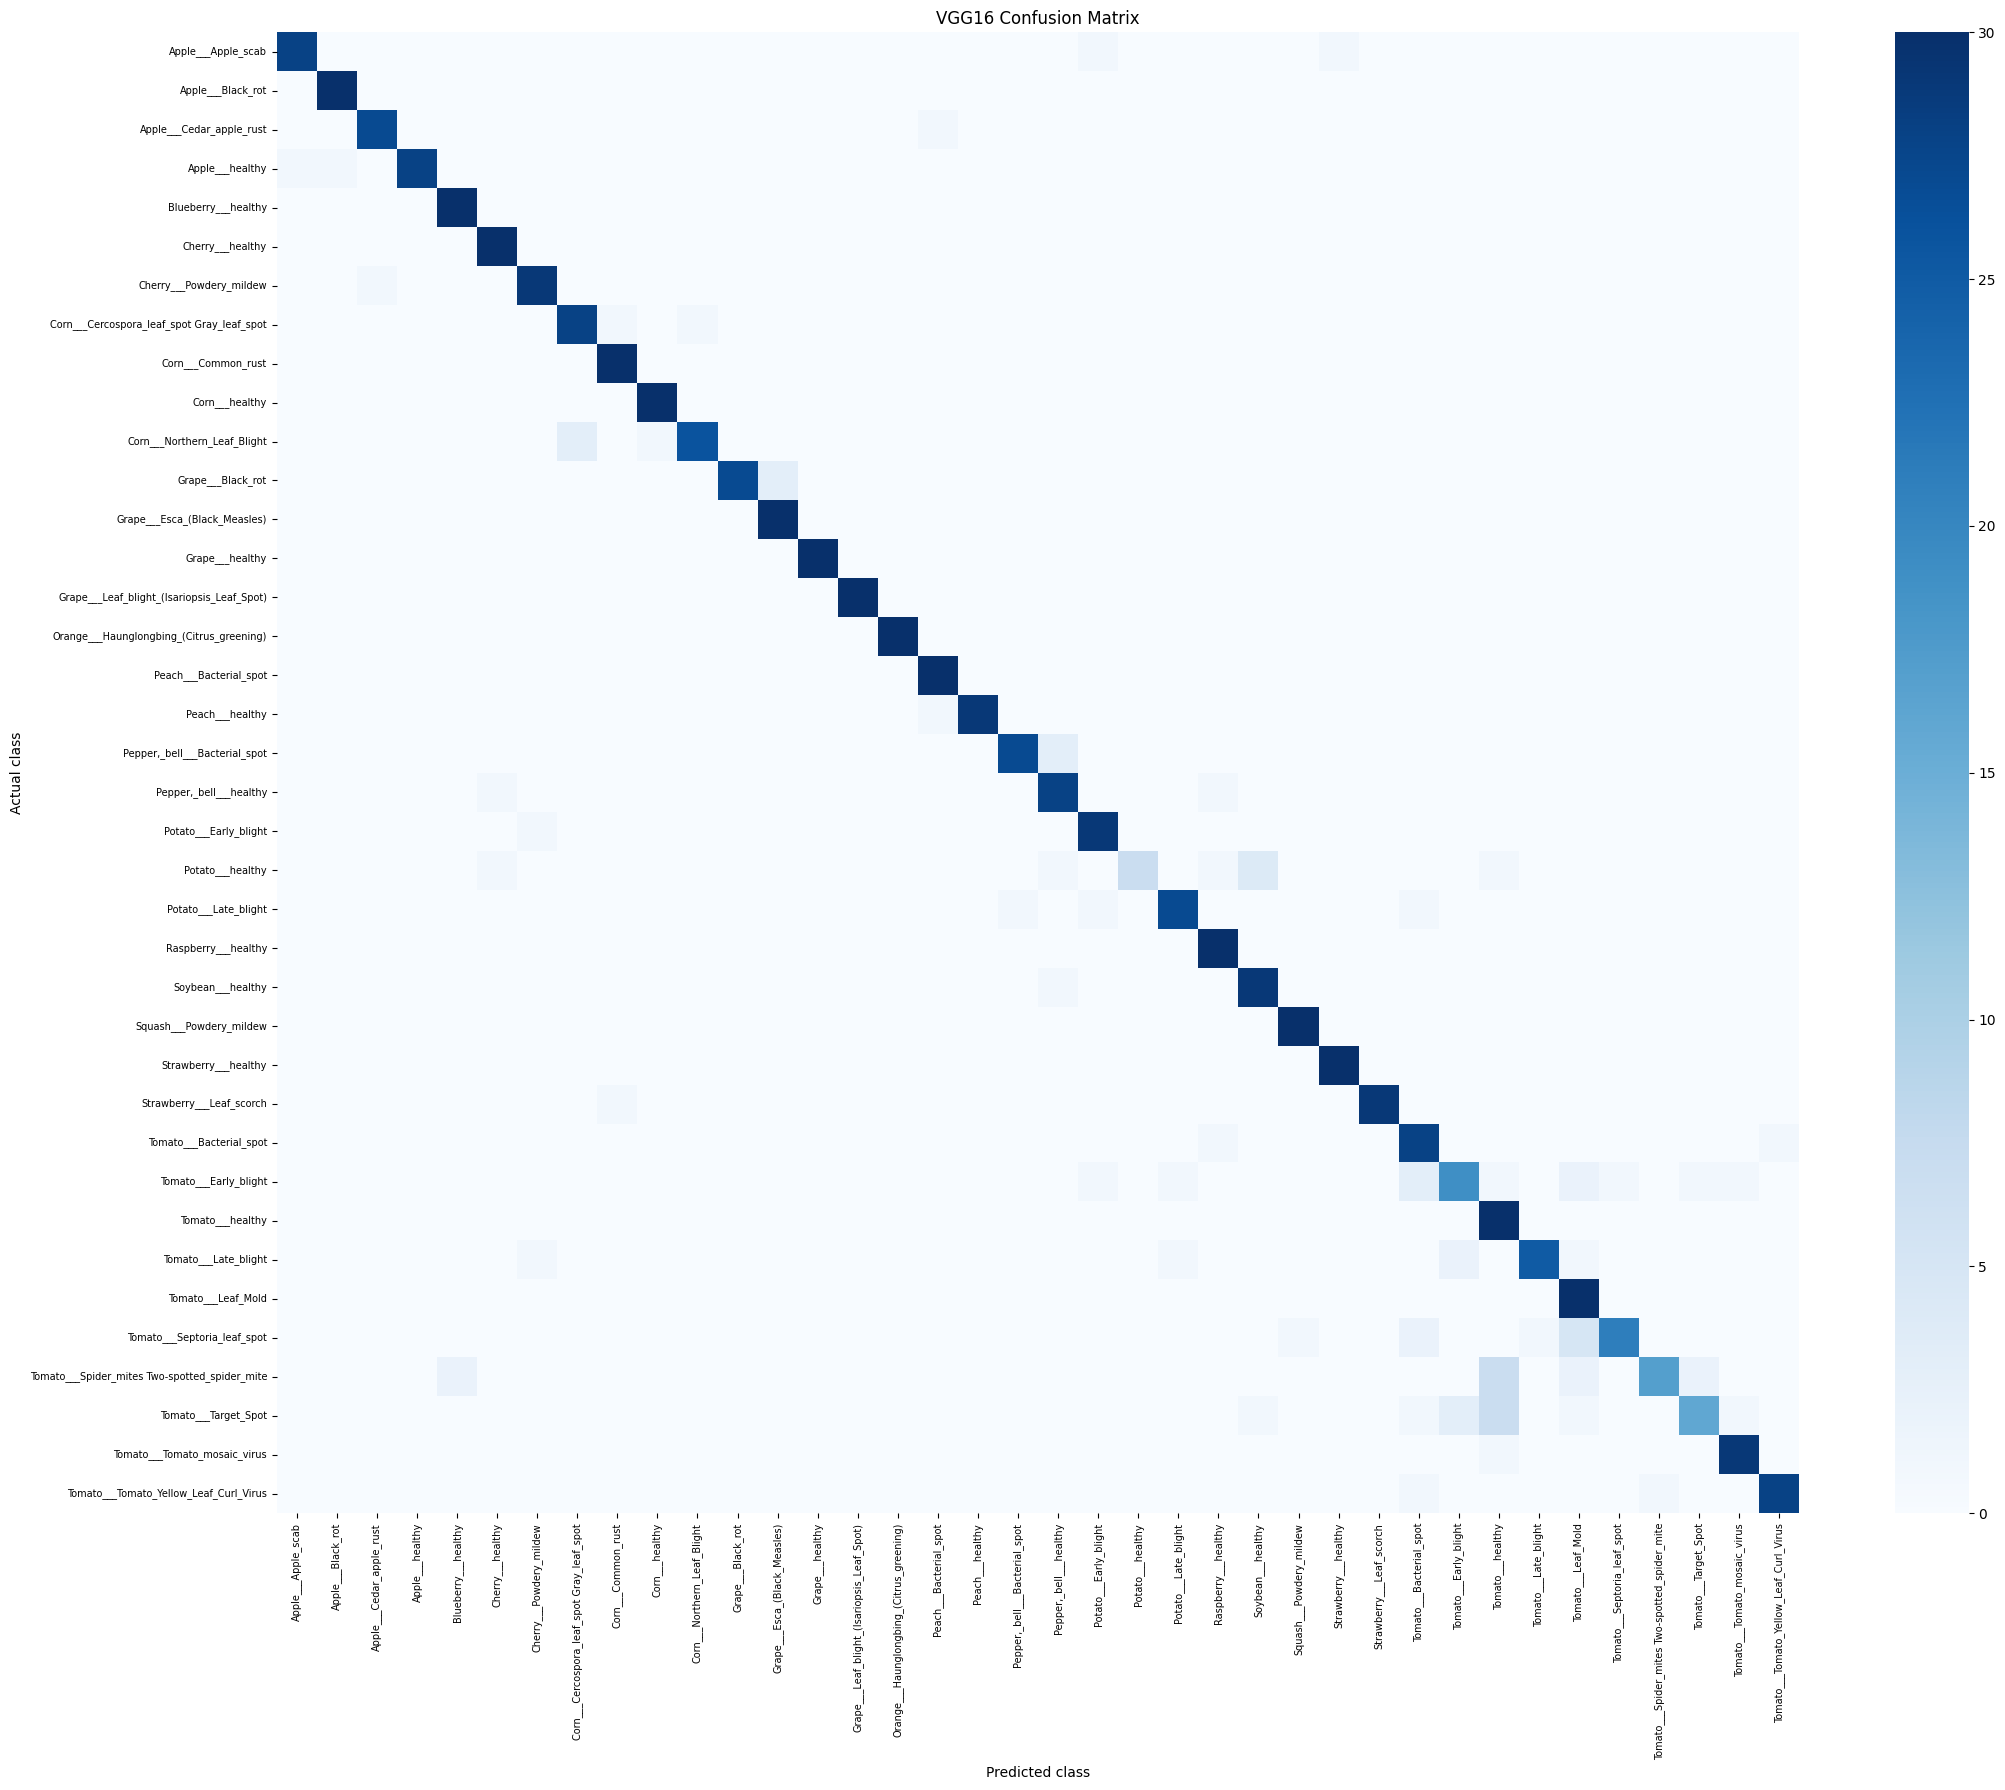


ResNet50 accuracy: 91.81%
Test samples: 1123


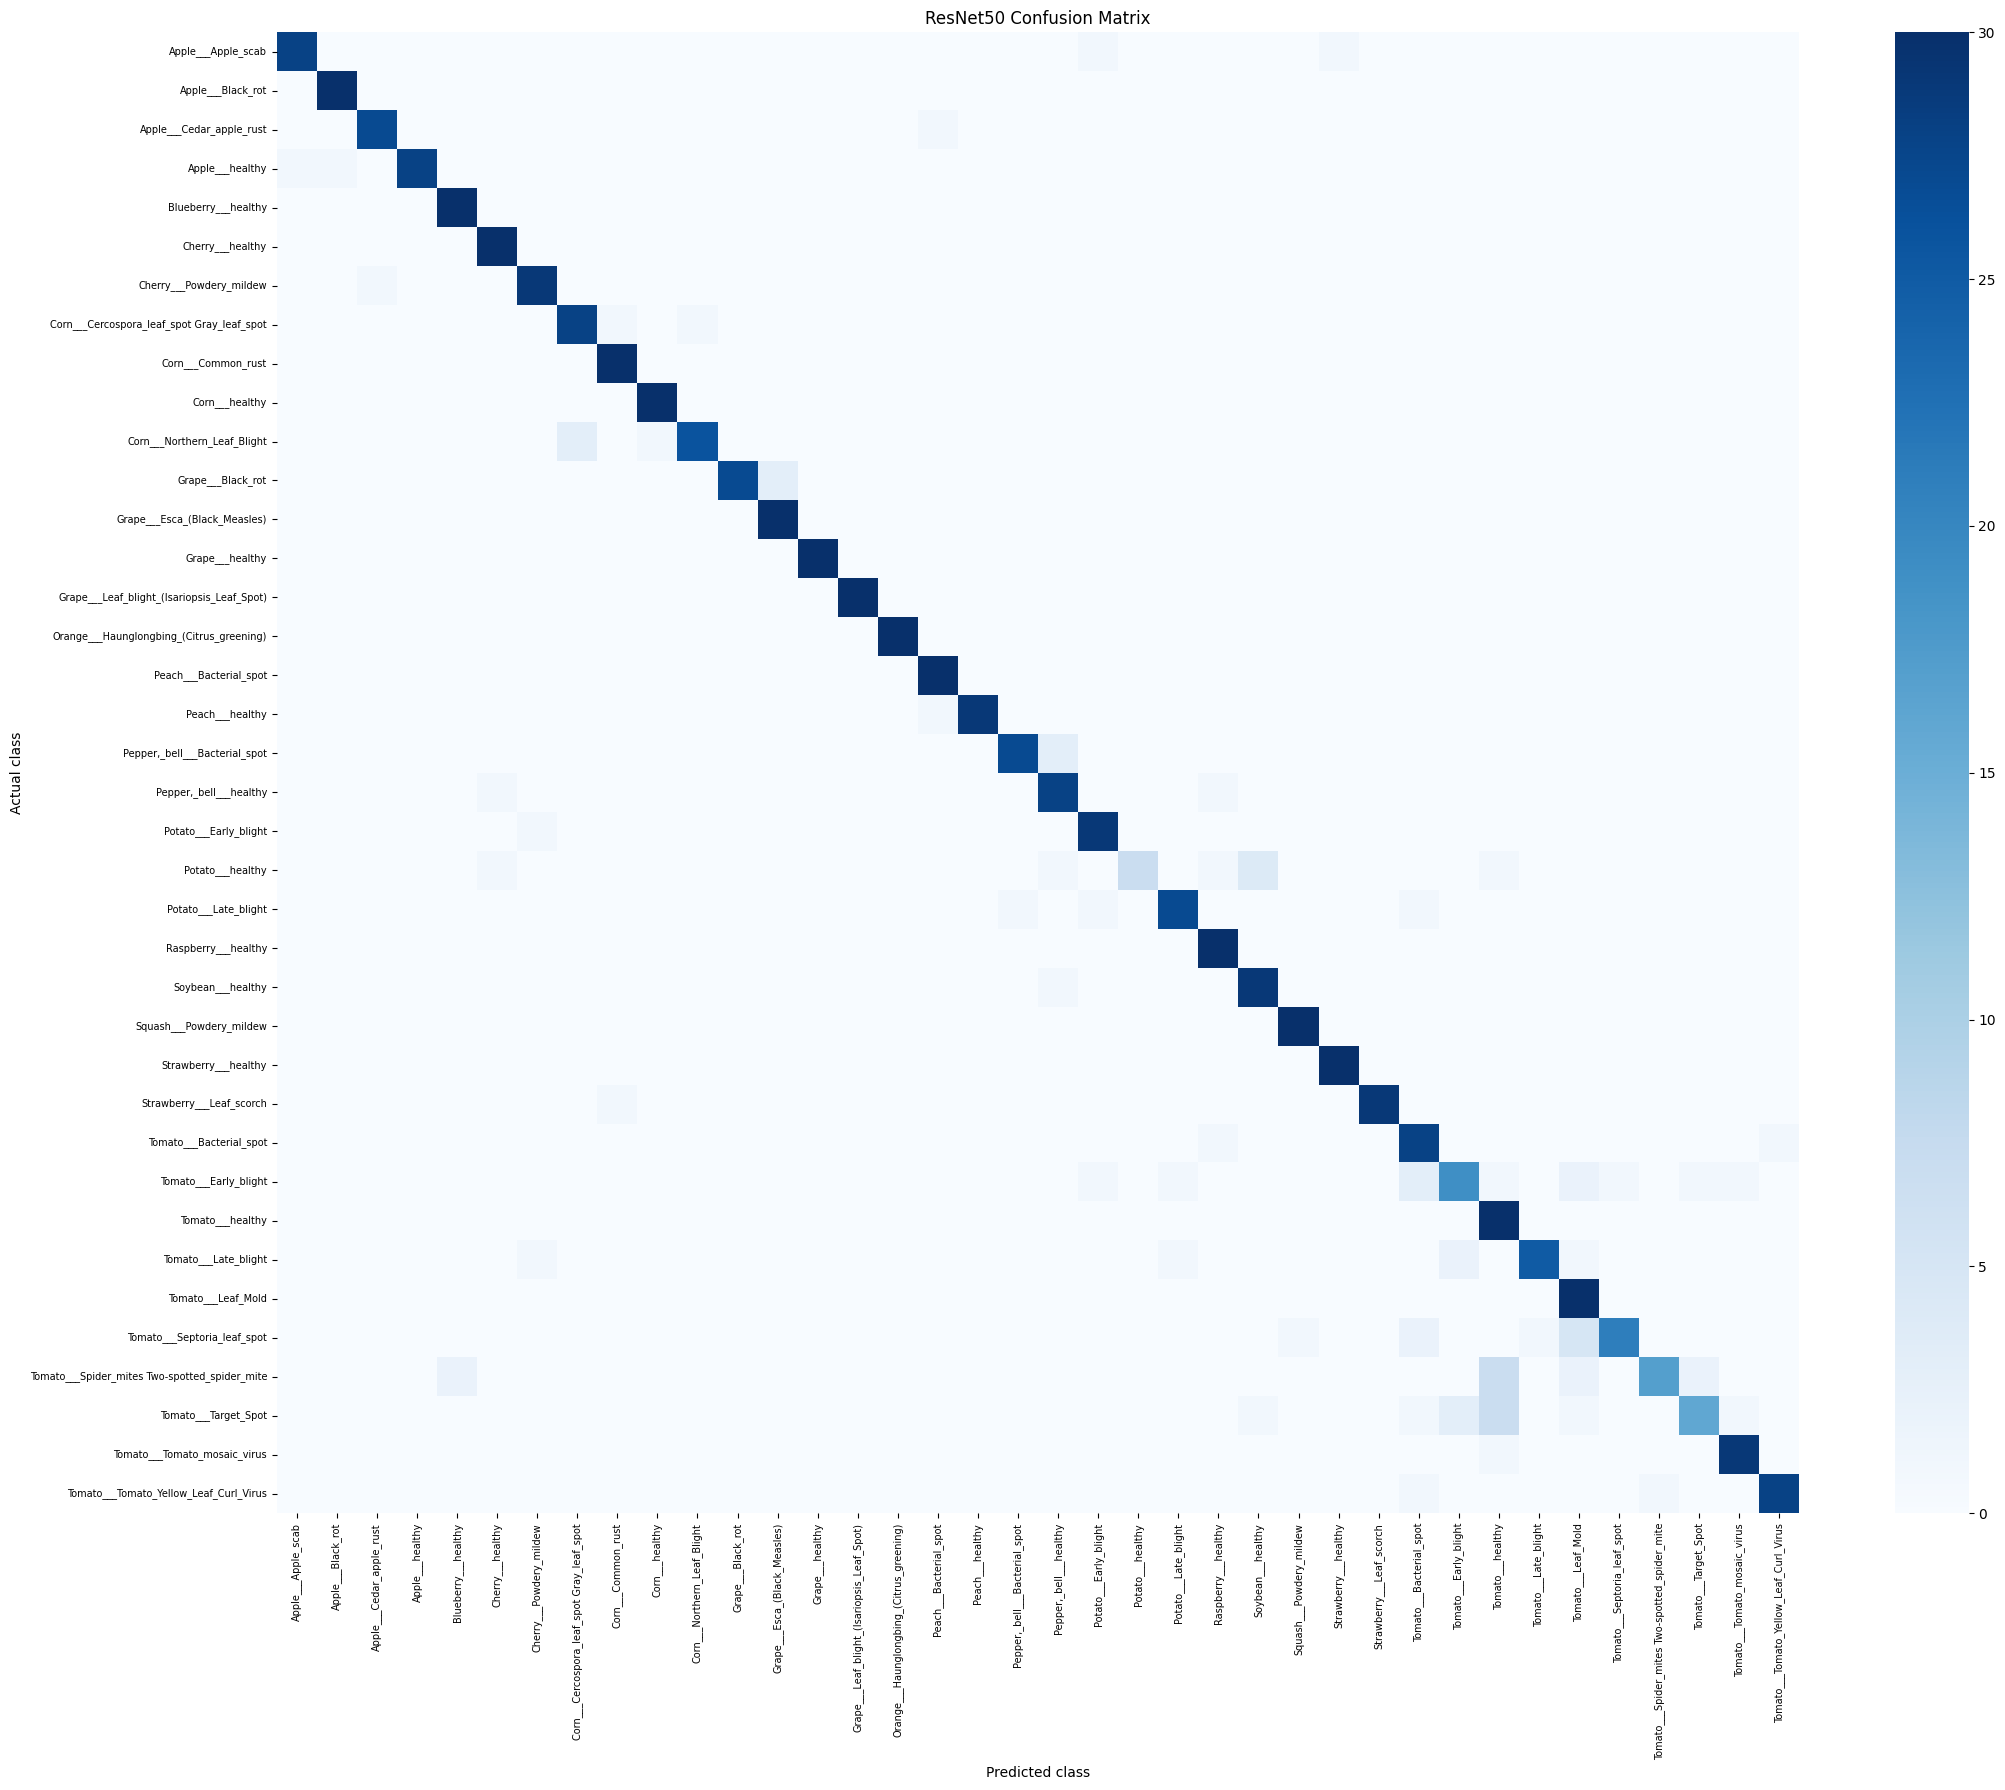

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score

models_to_check = [
    ("CNN", cnn_model, cnn_test),
    ("VGG16", best_model, vgg_test),
    ("ResNet50", resnet_model, resnet_test)
]

results = {}

for name, model, test_data in models_to_check:
    y_true, y_pred = [], []

    for images, labels in test_data:
        predictions = model.predict(images, verbose=0)
        y_true.extend(labels.numpy().astype(int).ravel())
        y_pred.extend(np.argmax(predictions, axis=1))

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = accuracy_score(y_true, y_pred)
    print(f"\n{name} accuracy: {accuracy * 100:.2f}%")
    print("Test samples:", len(y_true))

    results[name] = (y_true, y_pred)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=np.arange(len(class_names))
    )

    plt.figure(figsize=(22, 18))
    sns.heatmap(
        cm,
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"{name} Confusion Matrix")
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.xticks(rotation=90, fontsize=7)
    plt.yticks(rotation=0, fontsize=7)
    plt.tight_layout()
    plt.show()